# Notebook 3 — Can the Model Tell Us When It Is Wrong? (Uncertainty)

### Why uncertainty matters

In Notebook 2 our best model (M4) predicts the yield strength of a new alloy family with a typical error of about 270 MPa. But a single average hides something important: **some predictions are good and some are bad.** A materials scientist wants to know *which ones to trust*.

So instead of a single number like **"1250 MPa"**, we want the model to say **"1250 ± 400 MPa"**, and we want that **± range to be honest**.

### Four questions this notebook answers

| # | Question | How we check it |
|---|---|---|
| Q1 | **Ranking:** are predictions with large uncertainty really worse? | Compare the errors of confident vs. unconfident predictions |
| Q2 | **Calibration:** does a "95% interval" contain the true value 95% of the time? | Count how often the measured value falls inside the interval |
| Q3 | Does the model **know** when an alloy comes from a **new family**? | Compare uncertainty for new alloys vs. new families |
| Q4 | Can a simple **calibration step** fix the problems? | Re-scale the uncertainty and check Q2 again |

### Methods

* **Bootstrap ensemble (main method):** train 10 XGBoost models, each on a slightly different random resample of the training data. If they agree → confident; if they disagree → uncertain.
* **Random forest tree spread (comparison):** a random forest is already an ensemble of 300 trees, so we get a spread "for free".
* **Calibration:** learn a correction factor for the uncertainty on held-back training data.

We study the paper's two key models: **M0 (baseline)** and **M4 (hardness as extra training data, scenario B)** from Notebook 2.

## Step 1 — Import the libraries

In [1]:
import os
import re
import urllib.request
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pymatgen.core import Element
from scipy.stats import norm, spearmanr          # normal distribution and rank correlation
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
from xgboost import XGBRegressor

COLOR_BLUE   = "#2a78d6"
COLOR_ORANGE = "#eb6834"
COLOR_GREEN  = "#1baf7a"
COLOR_GRAY   = "#8a8a85"

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)
print("Libraries imported.")

Libraries imported.


## Step 2 — Data and features (same as Notebook 2)

This cell repeats Notebook 2, Steps 2–4 in compact form: helper functions, the strength table, the deduplicated hardness table, and the features. Nothing new happens here; see Notebook 2 for the detailed explanations.

In [2]:
# ---------- helper functions (explained in Notebooks 1 and 2) ----------
def parse_formula(formula):
    '''"Al0.25 Co1 Fe1 Ni1" -> atomic fractions {"Al": 0.077, ...}'''
    amounts = {}
    for element, amount in re.findall(r"([A-Z][a-z]?)([0-9.]+)", formula):
        amounts[element] = amounts.get(element, 0) + float(amount)
    total = sum(amounts.values())
    return {element: amount / total for element, amount in amounts.items()}

def make_composition_id(comp):
    return "-".join(f"{el}{round(frac, 3)}" for el, frac in sorted(comp.items()))

def make_system_id(comp):
    return "-".join(sorted(comp.keys()))

def element_radius(symbol):
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        radius = Element(symbol).metallic_radius
    return float(radius) if radius else float(Element(symbol).atomic_radius)

def valence_electrons(symbol):
    group = Element(symbol).group
    return group if group <= 12 else group - 10

def physics_descriptors(comp, table):
    elements = list(comp.keys())
    c   = np.array([comp[el] for el in elements])
    r   = table.loc[elements, "radius"].values
    chi = table.loc[elements, "electroneg"].values
    r_mean, chi_mean = np.sum(c * r), np.sum(c * chi)
    return {
        "delta_size_mismatch": 100 * np.sqrt(np.sum(c * (1 - r / r_mean) ** 2)),
        "S_mix":     -8.314 * np.sum(c * np.log(c)),
        "VEC":       np.sum(c * table.loc[elements, "vec"].values),
        "chi_mean":  chi_mean,
        "delta_chi": np.sqrt(np.sum(c * (chi - chi_mean) ** 2)),
        "Tm_mean":   np.sum(c * table.loc[elements, "melting_K"].values),
        "r_mean":    r_mean,
        "n_elements": len(elements),
    }

# ---------- load and clean ----------
DATA_FILE = "data/MPEA_dataset.csv"
if not os.path.exists(DATA_FILE):
    os.makedirs("data", exist_ok=True)
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/CitrineInformatics/MPEA_dataset/master/MPEA_dataset.csv", DATA_FILE)

raw = pd.read_csv(DATA_FILE).rename(columns={
    "IDENTIFIER: Reference ID": "ref_id", "FORMULA": "formula",
    "PROPERTY: Processing method": "processing", "PROPERTY: HV": "hardness_HV",
    "PROPERTY: Type of test": "test_type", "PROPERTY: Test temperature ($^\\circ$C)": "test_temp_C",
    "PROPERTY: YS (MPa)": "yield_strength_MPa"})
raw["processing"]     = raw["processing"].fillna("unknown")
raw["test_type"]      = raw["test_type"].fillna("unknown")
raw["composition"]    = raw["formula"].apply(parse_formula)
raw["composition_id"] = raw["composition"].apply(make_composition_id)
raw["system_id"]      = raw["composition"].apply(make_system_id)

strength = raw[raw["yield_strength_MPa"].notna() & raw["test_temp_C"].between(20, 30)]
strength = strength[(strength["yield_strength_MPa"] > 0) & (strength["yield_strength_MPa"] < 5000)].reset_index(drop=True)
hardness = raw[raw["hardness_HV"].notna()].drop_duplicates(
    subset=["composition_id", "processing", "hardness_HV", "ref_id"]).reset_index(drop=True)

# ---------- features for both tables at once ----------
both_tables = pd.concat([strength.assign(source="strength"),
                         hardness.assign(source="hardness", test_type="hardness")], ignore_index=True)
all_elements = sorted({el for comp in both_tables["composition"] for el in comp})
element_table = pd.DataFrame({
    "radius":     {el: element_radius(el) for el in all_elements},
    "electroneg": {el: float(Element(el).X) for el in all_elements},
    "melting_K":  {el: float(Element(el).melting_point) for el in all_elements},
    "vec":        {el: valence_electrons(el) for el in all_elements},
})
fractions  = pd.DataFrame(list(both_tables["composition"])).fillna(0).add_prefix("frac_")
physics    = pd.DataFrame([physics_descriptors(c, element_table) for c in both_tables["composition"]])
categories = pd.get_dummies(both_tables[["test_type", "processing"]], prefix=["test", "proc"], dtype=int)
features_all = pd.concat([fractions, physics, categories], axis=1)

is_strength_row   = (both_tables["source"] == "strength").values
X_strength        = features_all[is_strength_row].reset_index(drop=True)
X_hardness        = features_all[~is_strength_row].reset_index(drop=True)
y_strength        = strength["yield_strength_MPa"].values
y_hardness_pseudo = hardness["hardness_HV"].values * 9.807 / 3

print(f"Strength rows: {len(X_strength)},  hardness rows: {len(X_hardness)},  features: {X_strength.shape[1]}")

Strength rows: 722,  hardness rows: 516,  features: 45


## Step 3 — Settings and small helper functions

`make_training_set` builds the training data for **M0** (strength only) or **M4** (strength + all hardness pseudo-strengths with weight 0.5), exactly as in Notebook 2.

In [3]:
N_FOLDS       = 5
N_MODELS      = 10      # size of the bootstrap ensemble
PSEUDO_WEIGHT = 0.5
SEED          = 0

GROUPINGS = {"New alloy (composition)":   "composition_id",
             "New alloy family (system)": "system_id"}

def assign_group_folds(groups, n_folds, seed):
    '''Randomly give every group a fold number (same as Notebook 2).'''
    unique_groups = np.unique(groups)
    rng = np.random.default_rng(seed)
    rng.shuffle(unique_groups)
    return {group: i % n_folds for i, group in enumerate(unique_groups)}

def make_training_set(train_rows, method):
    '''
    train_rows: True/False array over the strength table (True = may be used for training).
    method: "M0" (strength only) or "M4" (strength + hardness pseudo-strengths).
    Returns features X, targets y and sample weights w.
    '''
    X = X_strength[train_rows]
    y = y_strength[train_rows]
    w = np.ones(train_rows.sum())
    if method == "M4":
        X = pd.concat([X, X_hardness])
        y = np.concatenate([y, y_hardness_pseudo])
        w = np.concatenate([w, np.full(len(y_hardness_pseudo), PSEUDO_WEIGHT)])
    return X, y, w

## Step 4 — The bootstrap ensemble

**Bootstrap** means: from a training set of *N* rows, randomly draw *N* rows **with replacement**. Some rows are picked twice, some not at all. Each of the 10 models sees a slightly different training set, so they make slightly different predictions.

* **Prediction** = the average of the 10 models.
* **Uncertainty (σ, "sigma")** = the standard deviation of the 10 predictions. Large σ means the models disagree.

In [4]:
def ensemble_predict(X_train, y_train, w_train, X_new, seed):
    '''Train N_MODELS XGBoost models on bootstrap resamples. Return mean and std of their predictions.'''
    rng = np.random.default_rng(seed)
    all_predictions = []

    for m in range(N_MODELS):
        # Draw row numbers with replacement (the "bootstrap" sample)
        rows = rng.integers(0, len(y_train), size=len(y_train))

        model = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5,
                             subsample=0.8, colsample_bytree=0.8,
                             random_state=seed * 100 + m, n_jobs=-1)
        model.fit(X_train.iloc[rows], y_train[rows], sample_weight=w_train[rows])
        all_predictions.append(model.predict(X_new))

    all_predictions = np.array(all_predictions)      # shape: (N_MODELS, number of new alloys)
    return all_predictions.mean(axis=0), all_predictions.std(axis=0)

## Step 5 — The calibration step

Ensembles are usually **overconfident**: their σ is too small. We fix this with a correction factor learned **only from training data** (never from the test fold, which would be cheating):

1. Inside the training data, hold back **20% of the groups** as a *calibration set*.
2. Train an ensemble on the other 80% and predict the calibration set.
3. For each calibration alloy compute $z = |\text{error}| / \sigma$: "how many sigmas off was the prediction?".
4. Find the value $q_{95}$ such that **95% of the z-values are below it**.
5. For the real test predictions, report the 95% interval as **prediction ± $q_{95}$ × σ**.

**A simpler alternative to compare with:** a *constant-width* interval, prediction ± $c_{95}$, where $c_{95}$ is the 95th percentile of the absolute errors on the calibration set. It uses no σ at all and gives every alloy the same interval. If our σ-based intervals are not narrower than this, then σ adds little practical value.

If the ensemble were perfectly calibrated, $q_{95}$ would be **1.96** (the textbook value for a normal distribution). A larger value means the raw σ was too small.

**Important detail:** the calibration groups are chosen with the **same grouping** as the test (alloy or family). This way the calibration "experiences" the same difficulty as the real test.

In [5]:
def calibration_factor(train_rows, groups, method, seed):
    '''Learn q95 (sigma-scaled) and c95 (constant width) on 20% held-back training groups.'''
    train_index  = np.where(train_rows)[0]
    inner_folds  = pd.Series(groups[train_index]).map(
        assign_group_folds(groups[train_index], 5, seed + 7)).values

    fit_rows = np.zeros(len(y_strength), dtype=bool)
    fit_rows[train_index[inner_folds != 0]] = True      # 80% of training groups
    calib_index = train_index[inner_folds == 0]           # 20% of training groups

    X, y, w = make_training_set(fit_rows, method)
    mean, sigma = ensemble_predict(X, y, w, X_strength.iloc[calib_index], seed)

    abs_error = np.abs(y_strength[calib_index] - mean)
    q95 = np.quantile(abs_error / sigma, 0.95)     # how many sigmas cover 95%
    c95 = np.quantile(abs_error, 0.95)             # how many MPa cover 95% (constant width)
    return q95, c95

## Step 6 — Run the experiment

For each grouping (new alloy / new family) and each method (M0 / M4) we do grouped 5-fold cross-validation. In every fold we:

* train the ensemble and predict the test alloys (mean and σ),
* learn the calibration factor $q_{95}$ from the training data,
* train a **random forest** too and record the spread of its 300 trees (comparison method).

This is the slowest notebook: about 2–4 minutes on a laptop.

In [6]:
results = {}     # results[(grouping, method)] = table with one row per strength measurement

for grouping_name, group_column in GROUPINGS.items():
    groups = strength[group_column].values
    fold   = pd.Series(groups).map(assign_group_folds(groups, N_FOLDS, SEED)).values

    for method in ["M0", "M4"]:
        mean  = np.zeros(len(y_strength))
        sigma = np.zeros(len(y_strength))
        q95   = np.zeros(len(y_strength))
        c95   = np.zeros(len(y_strength))
        rf_mean  = np.zeros(len(y_strength))
        rf_sigma = np.zeros(len(y_strength))

        for f in range(N_FOLDS):
            train, test = fold != f, fold == f
            X, y, w = make_training_set(train, method)

            # (1) bootstrap ensemble: prediction and raw uncertainty
            mean[test], sigma[test] = ensemble_predict(X, y, w, X_strength[test], SEED)

            # (2) calibration factor, learned from training data only
            q95[test], c95[test] = calibration_factor(train, groups, method, SEED)

            # (3) random forest: spread of the individual trees
            rf = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=SEED, n_jobs=-1)
            rf.fit(X, y, sample_weight=w)
            tree_predictions = np.array([tree.predict(X_strength[test].values) for tree in rf.estimators_])
            rf_mean[test], rf_sigma[test] = tree_predictions.mean(axis=0), tree_predictions.std(axis=0)

        results[(grouping_name, method)] = pd.DataFrame({
            "formula": strength["formula"], "system_id": strength["system_id"],
            "measured": y_strength, "pred": mean, "sigma": sigma, "q95": q95, "c95": c95,
            "rf_pred": rf_mean, "rf_sigma": rf_sigma,
        })
        print(f"done: {grouping_name:28s} {method}   R² = {r2_score(y_strength, mean):.3f}")

done: New alloy (composition)      M0   R² = 0.669


done: New alloy (composition)      M4   R² = 0.701


done: New alloy family (system)    M0   R² = 0.533


done: New alloy family (system)    M4   R² = 0.630


## Step 7 — Q1: Are uncertain predictions really worse?

Two simple checks:

1. **Spearman rank correlation** between σ and the absolute error. 0 = σ tells us nothing; 1 = σ perfectly orders the errors. Values of 0.2–0.4 are typical for materials data.
2. **Split in halves:** the 50% most confident predictions vs. the 50% least confident. If uncertainty is useful, the confident half should have a clearly smaller error.

In [7]:
def ranking_check(table, pred_col, sigma_col):
    error = np.abs(table["measured"] - table[pred_col])
    order = np.argsort(table[sigma_col].values)            # from most to least confident
    half  = len(order) // 2
    return {
        "Spearman(σ, error)":          spearmanr(table[sigma_col], error).correlation,
        "MAE all (MPa)":               error.mean(),
        "MAE confident half (MPa)":    error.iloc[order[:half]].mean(),
        "MAE uncertain half (MPa)":    error.iloc[order[half:]].mean(),
    }

rows = []
for (grouping_name, method), table in results.items():
    rows.append({"Grouping": grouping_name, "Method": method, "UQ": "XGB ensemble",
                 **ranking_check(table, "pred", "sigma")})
    rows.append({"Grouping": grouping_name, "Method": method, "UQ": "Random forest",
                 **ranking_check(table, "rf_pred", "rf_sigma")})

ranking_table = pd.DataFrame(rows).set_index(["Grouping", "Method", "UQ"])
ranking_table.round(2)

Spearman(σ, error)  \
Grouping                  Method UQ                                  
New alloy (composition)   M0     XGB ensemble                 0.30   
                                 Random forest                0.25   
                          M4     XGB ensemble                 0.28   
                                 Random forest                0.30   
New alloy family (system) M0     XGB ensemble                 0.25   
                                 Random forest                0.26   
                          M4     XGB ensemble                 0.26   
                                 Random forest                0.32   

                                                MAE all (MPa)  \
Grouping                  Method UQ                             
New alloy (composition)   M0     XGB ensemble          248.87   
                                 Random forest         262.28   
                          M4     XGB ensemble          241.74   
                                 Random forest         252.20   
New alloy family (system) M0     XGB ensemble          301.03   
                                 Random forest         319.59   
                          M4     XGB ensemble          271.89   
                                 Random forest         300.69   

                                                MAE confident half (MPa)  \
Grouping                  Method UQ                                        
New alloy (composition)   M0     XGB ensemble                     192.67   
                                 Random forest                    208.05   
                          M4     XGB ensemble                     186.82   
                                 Random forest                    188.85   
New alloy family (system) M0     XGB ensemble                     251.68   
                                 Random forest                    266.29   
                          M4     XGB ensemble                     214.15   
                                 Random forest                    228.87   

                                                MAE uncertain half (MPa)  
Grouping                  Method UQ                                       
New alloy (composition)   M0     XGB ensemble                     305.07  
                                 Random forest                    316.50  
                          M4     XGB ensemble                     296.66  
                                 Random forest                    315.54  
New alloy family (system) M0     XGB ensemble                     350.37  
                                 Random forest                    372.90  
                          M4     XGB ensemble                     329.62  
                                 Random forest                    372.50

### Step 7b — The "confidence curve"

Imagine you only trust the model's most confident predictions and send the rest to the lab. How does the error of the predictions you keep change as you remove more and more uncertain ones?

* **Orange (our model):** remove predictions in order of largest σ.
* **Gray dashed (random):** remove predictions in random order. The error stays flat; this is the "no information" baseline.
* **Green dotted (perfect):** remove the predictions with the largest *true* errors. This is the best possible, impossible in practice because we don't know true errors in advance.

The closer the orange line is to the green one, the more useful the uncertainty.

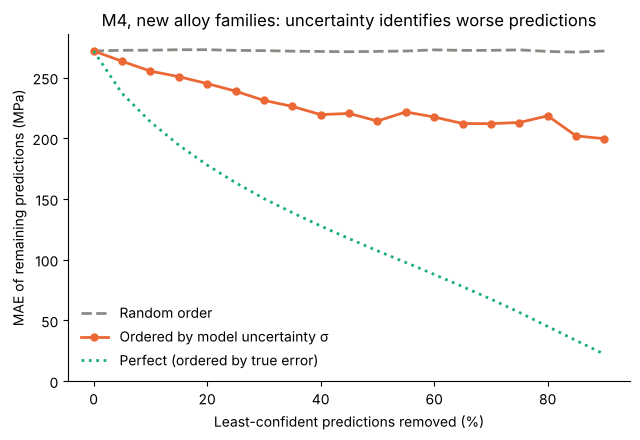

In [8]:
def confidence_curve(errors, order, fractions):
    '''MAE of the predictions that remain after removing the first part of `order`.'''
    n = len(errors)
    return [errors[order[: max(1, int(round(n * (1 - f))))]].mean() for f in fractions]

table  = results[("New alloy family (system)", "M4")]
errors = np.abs(table["measured"] - table["pred"]).values
removed = np.linspace(0, 0.9, 19)    # remove 0%, 5%, ..., 90% of predictions

curve_model   = confidence_curve(errors, np.argsort(table["sigma"].values), removed)  # small sigma first
curve_perfect = confidence_curve(errors, np.argsort(errors), removed)                  # small error first
rng = np.random.default_rng(0)
curve_random  = np.mean([confidence_curve(errors, rng.permutation(len(errors)), removed) for _ in range(50)], axis=0)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(removed * 100, curve_random,  color=COLOR_GRAY,   linestyle="--", linewidth=2, label="Random order")
ax.plot(removed * 100, curve_model,   color=COLOR_ORANGE, linewidth=2, marker="o", markersize=5, label="Ordered by model uncertainty σ")
ax.plot(removed * 100, curve_perfect, color=COLOR_GREEN,  linestyle=":", linewidth=2, label="Perfect (ordered by true error)")
ax.set_xlabel("Least-confident predictions removed (%)")
ax.set_ylabel("MAE of remaining predictions (MPa)")
ax.set_title("M4, new alloy families: uncertainty identifies worse predictions")
ax.set_ylim(bottom=0)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig("figures/fig7_confidence_curve.png", dpi=300)
plt.show()

## Step 8 — Q2 & Q4: Is the uncertainty calibrated?

For each prediction we build a **95% interval** in two ways:

* **Raw:** prediction ± 1.96 σ (what you would naively do)
* **Calibrated:** prediction ± $q_{95}$ σ (Step 5)

Then we count the **coverage**: the % of measured values that fall inside their interval. **The goal is 95%.** Below 95% = overconfident (intervals too narrow); above = too cautious.

In [9]:
def coverage(table, pred_col, half_width):
    '''Fraction of measured values inside prediction ± half_width.'''
    return np.mean(np.abs(table["measured"] - table[pred_col]) <= half_width)

rows = []
for (grouping_name, method), table in results.items():
    rows.append({
        "Grouping": grouping_name, "Method": method,
        "Coverage raw XGB (%)":        100 * coverage(table, "pred", 1.96 * table["sigma"]),
        "Coverage raw RF (%)":         100 * coverage(table, "rf_pred", 1.96 * table["rf_sigma"]),
        "Coverage calibrated XGB (%)": 100 * coverage(table, "pred", table["q95"] * table["sigma"]),
        "Mean q95 (ideal 1.96)":       table["q95"].mean(),
        "Half-width calibrated σ (MPa)": (table["q95"] * table["sigma"]).mean(),
        "Coverage constant width (%)": 100 * coverage(table, "pred", table["c95"]),
        "Half-width constant (MPa)":   table["c95"].mean(),
    })
calibration_table = pd.DataFrame(rows).set_index(["Grouping", "Method"])
calibration_table.round(1)

Coverage raw XGB (%)  Coverage raw RF (%)  \
Grouping                  Method                                              
New alloy (composition)   M0                      49.6                 90.9   
                          M4                      47.1                 90.4   
New alloy family (system) M0                      39.8                 87.4   
                          M4                      42.1                 90.0   

                                  Coverage calibrated XGB (%)  \
Grouping                  Method                                
New alloy (composition)   M0                             94.2   
                          M4                             89.3   
New alloy family (system) M0                             90.2   
                          M4                             94.6   

                                  Mean q95 (ideal 1.96)  \
Grouping                  Method                          
New alloy (composition)   M0                        7.4   
                          M4                        6.5   
New alloy family (system) M0                        7.6   
                          M4                        8.1   

                                  Half-width calibrated σ (MPa)  \
Grouping                  Method                                  
New alloy (composition)   M0                              752.5   
                          M4                              642.9   
New alloy family (system) M0                              778.7   
                          M4                              793.1   

                                  Coverage constant width (%)  \
Grouping                  Method                                
New alloy (composition)   M0                             93.1   
                          M4                             92.0   
New alloy family (system) M0                             91.8   
                          M4                             92.4   

                                  Half-width constant (MPa)  
Grouping                  Method                             
New alloy (composition)   M0                          626.6  
                          M4                          586.8  
New alloy family (system) M0                          804.2  
                          M4                          696.3

**How to read this table:**
* *Coverage raw XGB* far below 95% → the raw ensemble is overconfident.
* *Mean q95* far above 1.96 → the raw σ must be multiplied by a large factor to become honest.
* Compare the two **half-widths**: if the σ-based interval is about as wide as the constant one, σ helps us **rank** predictions (Step 7) but does not make the intervals much **narrower**.

### Step 8b — Calibration curve

A single 95% check is not the whole story, so we repeat the coverage check for **every** confidence level from 10% to 95%. A perfectly calibrated model lies on the diagonal. Points **below** the diagonal mean the model is overconfident.

For the calibrated version we turn $q_{95}$ into a corrected sigma: $\sigma_{cal} = \sigma \times q_{95} / 1.96$.

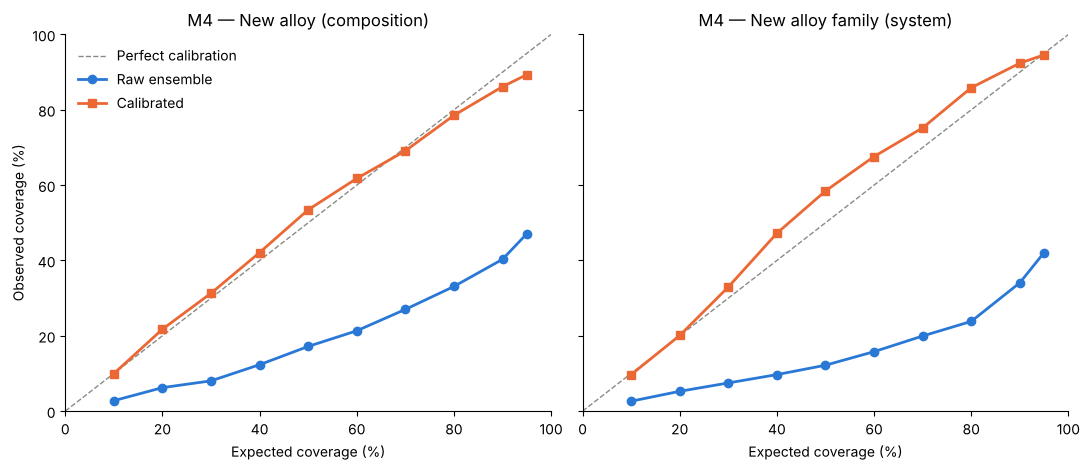

In [10]:
levels = np.array([0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 0.95])
z_values = norm.ppf(0.5 + levels / 2)        # e.g. 95% -> 1.96, 68% -> 1.0

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8), sharey=True)
for ax, grouping_name in zip(axes, GROUPINGS):
    table = results[(grouping_name, "M4")]
    error = np.abs(table["measured"] - table["pred"]).values
    sigma_raw = table["sigma"].values
    sigma_cal = sigma_raw * table["q95"].values / 1.96

    observed_raw = [np.mean(error <= z * sigma_raw) for z in z_values]
    observed_cal = [np.mean(error <= z * sigma_cal) for z in z_values]

    ax.plot([0, 100], [0, 100], color=COLOR_GRAY, linestyle="--", linewidth=1, label="Perfect calibration")
    ax.plot(levels * 100, np.array(observed_raw) * 100, color=COLOR_BLUE, marker="o", linewidth=2, label="Raw ensemble")
    ax.plot(levels * 100, np.array(observed_cal) * 100, color=COLOR_ORANGE, marker="s", linewidth=2, label="Calibrated")
    ax.set_title(f"M4 — {grouping_name}")
    ax.set_xlabel("Expected coverage (%)")
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.spines[["top", "right"]].set_visible(False)

axes[0].set_ylabel("Observed coverage (%)")
axes[0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.savefig("figures/fig8_calibration_curves.png", dpi=300)
plt.show()

## Step 9 — Q3: Does the model know when an alloy family is new?

Predicting a new alloy *family* is harder than predicting a new alloy, so the errors are larger (Notebook 1 and 2). An honest uncertainty should therefore also be **larger** for new families. Let's compare the average error with the average raw and calibrated uncertainty.

In [11]:
rows = []
for (grouping_name, method), table in results.items():
    rows.append({
        "Grouping": grouping_name, "Method": method,
        "Mean |error| (MPa)":          np.abs(table["measured"] - table["pred"]).mean(),
        "Mean raw σ (MPa)":            table["sigma"].mean(),
        "Mean calibrated σ (MPa)":     (table["sigma"] * table["q95"] / 1.96).mean(),
    })
q3_table = pd.DataFrame(rows).set_index(["Grouping", "Method"])
q3_table.round(0)

Mean |error| (MPa)  Mean raw σ (MPa)  \
Grouping                  Method                                         
New alloy (composition)   M0                   249.0             103.0   
                          M4                   242.0              99.0   
New alloy family (system) M0                   301.0             101.0   
                          M4                   272.0              98.0   

                                  Mean calibrated σ (MPa)  
Grouping                  Method                           
New alloy (composition)   M0                        384.0  
                          M4                        328.0  
New alloy family (system) M0                        397.0  
                          M4                        405.0

**How to read this:** if the raw σ is almost the same for both groupings while the error grows, the ensemble **cannot tell** that a family is new. All 10 models were trained on similar data, so they make the same mistakes together. The calibration step learns this from the held-back *families* and widens the intervals accordingly. This is why the calibration must use the **same grouping** as the real use case.

## Step 9b — Why are the intervals so wide? Noise in the data itself

Even a perfect model cannot be more precise than the data it learns from. The same alloy, measured by different labs (different casting, grain size, sample size, oxygen content), gives different yield strengths. Let's measure this **scatter between repeated measurements**, using alloys tested at least 3 times with the **same test type**.

In [12]:
scatter = (strength.groupby(["composition_id", "test_type"])["yield_strength_MPa"]
                   .agg(["count", "mean", "std"])
                   .query("count >= 3")
                   .sort_values("count", ascending=False))

print(f"Alloys measured at least 3 times with the same test: {len(scatter)}")
print(f"Typical (median) standard deviation between repeats: {scatter['std'].median():.0f} MPa")
print(f"Average standard deviation between repeats:          {scatter['std'].mean():.0f} MPa\n")
scatter.head(8).round(0)

Alloys measured at least 3 times with the same test: 58
Typical (median) standard deviation between repeats: 194 MPa
Average standard deviation between repeats:          211 MPa



,,count,mean,std
composition_id,test_type,,,
Co0.2-Cr0.2-Fe0.2-Mn0.2-Ni0.2,T,30,654.0,422.0
Hf0.2-Nb0.2-Ta0.2-Ti0.2-Zr0.2,T,27,1077.0,248.0
Al0.2-Co0.2-Cr0.2-Fe0.2-Ni0.2,C,23,1275.0,237.0
Cr0.2-Cu0.2-Fe0.2-Mn0.2-Ni0.2,T,13,734.0,269.0
Al0.071-Co0.232-Cr0.232-Fe0.232-Ni0.232,T,12,378.0,221.0
Co0.25-Cr0.25-Fe0.25-Ni0.25,T,10,323.0,170.0
Al0.07-Co0.233-Cr0.233-Fe0.233-Ni0.233,T,8,463.0,346.0
Co0.2-Cr0.2-Fe0.2-Mn0.2-Ni0.2,C,8,719.0,536.0


This scatter is the **noise floor**: part of the "error" of every model is simply disagreement between experiments. It's one reason why 95% intervals cannot be narrow with literature data, and a fair point to make in the paper's discussion. (Processing, grain size and impurities explain part of the scatter; most of that information is missing in the dataset.)

## Step 10 — What a prediction looks like in practice

Here are predictions for a few alloys from **new families** (M4, calibrated 95% intervals), as you might report them to an experimental colleague.

In [13]:
table = results[("New alloy family (system)", "M4")].copy()
table["95% interval ±"] = table["q95"] * table["sigma"]
table["inside?"] = np.where(np.abs(table["measured"] - table["pred"]) <= table["95% interval ±"], "yes", "NO")

# 10 random examples, rounded to whole MPa
examples = table.sample(10, random_state=1)[["formula", "measured", "pred", "95% interval ±", "inside?"]]
examples = examples.rename(columns={"measured": "Measured (MPa)", "pred": "Predicted (MPa)"})
examples.round(0)

,formula,Measured (MPa),Predicted (MPa),95% interval ±,inside?
59,Al0.56 Co1 Cr1 Fe1 Mn1 Ni1,526.0,972.0,1638.0,yes
60,Al0.62 Co1 Cr1 Fe1 Mn1 Ni1,833.0,1134.0,723.0,yes
214,Hf1 Nb1 Ta1 Ti1 Zr1,1202.0,1165.0,478.0,yes
638,Al0.6 Cr1 Fe1 Mn1 Ni1,1130.0,1166.0,639.0,yes
8,Co1 Fe1 Ni1 Si0.75,1301.0,1325.0,2176.0,yes
101,Al1 Mo1 Nb1 Ti1 V1,1375.0,1391.0,694.0,yes
474,Co1 Cr1 Fe1 Ni1,494.0,432.0,1064.0,yes
161,Cu1 Mn1 Ni1 Zn0.333,215.0,378.0,939.0,yes
406,Co1 Ni1 V1,602.0,808.0,959.0,yes
509,Al0.278 Co0.694 Cr0.222 Fe0.417 Ni1 Ti0.167,627.0,908.0,578.0,yes


## Step 11 — Save the results

In [14]:
ranking_table.round(3).to_csv("results/table4_uncertainty_ranking.csv")
calibration_table.round(3).to_csv("results/table5_calibration.csv")
q3_table.round(1).to_csv("results/table6_uncertainty_new_family.csv")

all_predictions = []
for (grouping_name, method), table in results.items():
    all_predictions.append(table.assign(Grouping=grouping_name, Method=method))
pd.concat(all_predictions).to_csv("results/predictions_with_uncertainty.csv", index=False)
print("Saved tables 4-6 and predictions_with_uncertainty.csv in results/")

Saved tables 4-6 and predictions_with_uncertainty.csv in results/


## Summary — what we learned

Compare these points with your own tables above. They describe the pattern we observed when writing this notebook:

1. **Q1, ranking:** uncertainty is **useful but not perfect**. The confident half of the predictions has a clearly smaller error than the uncertain half, and the confidence curve lies between "random" and "perfect".
2. **Q2, calibration:** the **raw XGBoost ensemble is strongly overconfident.** Its "95%" intervals contain the true strength only about half of the time. The random forest's tree spread is much better calibrated without any correction (about 90%), a useful practical tip.
3. **Q3, new families:** the raw ensemble's σ **does not grow** for new alloy families even though the errors do. The model does not "know" when it is extrapolating.
4. **Q4, fix:** a simple calibration on held-back training groups (using the same grouping as the test) brings coverage **close to the 95% target**.
5. **But the honest intervals are wide** (several hundred MPa), about as wide as a simple constant-width interval. A large part of this comes from scatter between repeated experiments on the same alloy (Step 9b), not only from the model.

> **📝 For your paper**
> * **Methods:** bootstrap ensemble (10 XGBoost models), random-forest tree spread as comparison, group-aware calibration with $q_{95}$ learned on 20% held-back training groups.
> * **Results:** Table 4 (ranking), Table 5 (coverage), Figure 7 (confidence curve), Figure 8 (calibration curves).
> * Report the scatter between repeated measurements (Step 9b) as the **noise floor** of the dataset; it puts the model errors in perspective.
> * **Key sentence:** *"Uncalibrated ensemble uncertainties are overconfident and do not reflect the additional difficulty of extrapolating to unseen alloy systems; a group-aware recalibration restores near-nominal coverage."*
> * **Limitation:** results are from one random split (seed 0) because the ensemble is slow. If you have time, repeat with seeds 1–4 (change `SEED`) and report mean ± std, as in Notebook 2.

### Next: Notebook 4 — Interpretation (SHAP)
Which descriptors drive yield strength, and does adding hardness data change what the model learns?

### Exercises (optional)
* Change `N_MODELS` to 5 or 20. Does the ranking or calibration change?
* Calibrate with `composition_id` groups but test on `system_id` groups. What happens to coverage? (This shows why the grouping must match.)